# **Simpson's Paradox**

**When the Aggregate Tells a Different Story**
___

**Statistical Simulation | Probability and Statistical Inference**
___

Imagine two medical treatments being evaluated for their effectiveness in treating kidney stones. Researchers compare their success rates and discover something seemingly straightforward: Treatment A performs better than Treatment B.

However, when the patients are divided into two groups according to the size of their kidney stones, an unexpected result emerges. Treatment A performs better in both groups individually, yet Treatment B has a higher overall success rate.

Both conclusions are mathematically correct, but they tell very different stories.

This phenomenon is known as **Simpson's Paradox**, a statistical phenomenon in which a trend observed across multiple individual groups reverses or disappears when those groups are combined.

The reversal is not caused by an arithmetic error. It emerges from differences in the composition of the groups being compared.

This notebook investigates the phenomenon through a classic medical example, reconstructs the underlying dataset, and uses statistical simulation to understand how aggregation can fundamentally change the interpretation of data.

**Central question:** How can a treatment outperform another in every subgroup and still appear inferior in the overall population?

___
## **1. The Medical Scenario**

Consider a clinical study comparing two treatments for patients suffering from kidney stones. Patients are classified into two categories based on stone size:

- **Small stones:** Generally associated with less complicated treatment outcomes.
- **Large stones:** Generally more difficult to treat successfully.

The study compares two alternative treatments, labelled Treatment A and Treatment B. The following results are observed:

| Stone size | Treatment | Successful treatments | Total patients |
|---|---|---:|---:|
| Small | A | 81 | 87 |
| Small | B | 234 | 270 |
| Large | A | 192 | 263 |
| Large | B | 55 | 80 |

At this stage, the data appears relatively ordinary. We have two treatments, two patient groups and a measurable outcome: whether the treatment successfully removes the kidney stone.

However, the distribution of patients across the groups is substantially different. Treatment A was administered predominantly to patients with large stones, whereas Treatment B was administered predominantly to patients with small stones.

That difference in patient composition will become central to our investigation.

**Important:** This is an observational example, not a randomized clinical trial. The treatment outcomes and patient distributions are used to demonstrate a statistical phenomenon. The results should not be interpreted as medical recommendations or evidence that one treatment is clinically preferable.

___

## **2. Research Questions**

We will investigate the data from two perspectives.

**First, the aggregate perspective:** What happens when all patients receiving Treatment A are compared with all patients receiving Treatment B, without considering stone size?

**Second, the subgroup perspective:** What happens when treatment success is evaluated separately for patients with small and large stones?

Our primary metric will be the treatment success rate:

$$
\text{Success Rate} =
\frac{\text{Successful Treatments}}
{\text{Total Treatments}}
$$

We will then investigate whether the two comparisons produce consistent conclusions.

The objective is not simply to identify which treatment has the higher success rate. It is to understand why the same dataset can produce apparently contradictory conclusions depending on how the observations are grouped.

___
**Import Libraries and set visualisation identity**

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.ticker import PercentFormatter
from matplotlib.patches import Patch

In [5]:
PALETTE = {
    "paper": "#F6F4EF",
    "surface": "#FFFFFF",
    "ink": "#242A2E",
    "muted": "#777D80",
    "grid": "#E5E1D9",
    "terracotta": "#C46D4E",
    "teal": "#397C78",
    "gold": "#C69A47",
    "soft_red": "#E9D4CA",
    "soft_teal": "#D7E6E2"
}

plt.rcParams.update({
    "figure.facecolor": PALETTE["paper"],
    "axes.facecolor": PALETTE["surface"],
    "axes.edgecolor": PALETTE["grid"],
    "axes.labelcolor": PALETTE["ink"],
    "axes.titlecolor": PALETTE["ink"],
    "xtick.color": PALETTE["muted"],
    "ytick.color": PALETTE["muted"],
    "text.color": PALETTE["ink"],
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 15,
    "axes.labelsize": 11,
    "axes.titleweight": "semibold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.spines.bottom": True,
    "axes.linewidth": 0.8,
    "grid.color": PALETTE["grid"],
    "grid.linewidth": 0.7,
    "figure.dpi": 130,
    "savefig.dpi": 350,
    "savefig.facecolor": PALETTE["paper"],
    "savefig.bbox": "tight"
})

sns.set_theme(
    style="white",
    rc=plt.rcParams
)

___
**Constructing the original dataset**

We will represent the data in grouped form, this is the original information we will use throughout the notebook.

In [7]:
grouped_data = pd.DataFrame({
    "Stone Size": ["Small", "Small", "Large", "Large"],
    "Treatment": ["A", "B", "A", "B"],
    "Successes": [81, 234, 192, 55],
    "Total Patients": [87, 270, 263, 80]
})

grouped_data["Failures"] = (
    grouped_data["Total Patients"]
    - grouped_data["Successes"]
)

grouped_data["Success Rate"] = (
    grouped_data["Successes"]
    / grouped_data["Total Patients"]
)

grouped_data["Failure Rate"] = (
    grouped_data["Failures"]
    / grouped_data["Total Patients"]
)

grouped_data

,Stone Size,Treatment,Successes,Total Patients,Failures,Success Rate,Failure Rate
0,Small,A,81,87,6,0.931034,0.068966
1,Small,B,234,270,36,0.866667,0.133333
2,Large,A,192,263,71,0.730038,0.269962
3,Large,B,55,80,25,0.687500,0.312500


___
**Inspect the treatment outcomes**

In [9]:
grouped_data.style.format({
    "Success Rate": "{:.2%}",
    "Failure Rate": "{:.2%}"
}).background_gradient(
    subset=["Success Rate"],
    cmap="YlGn"
)

,Stone Size,Treatment,Successes,Total Patients,Failures,Success Rate,Failure Rate
0,Small,A,81,87,6,93.10%,6.90%
1,Small,B,234,270,36,86.67%,13.33%
2,Large,A,192,263,71,73.00%,27.00%
3,Large,B,55,80,25,68.75%,31.25%


___

### **Initial Observations**

The dataset contains 700 patients divided across two treatments and two stone-size categories.

A first inspection reveals that the treatments were not applied to comparable patient populations.

Treatment A was administered to 263 patients with large stones and 87 patients with small stones. Treatment B was administered to 80 patients with large stones and 270 patients with small stones.

Consequently, the distribution of patient severity differs considerably between the two treatment groups.

This is an important detail because stone size is associated with the probability of successful treatment. Large stones generally present a more difficult treatment scenario than small stones.

Before drawing conclusions about treatment effectiveness, we therefore need to examine whether the difference in patient composition is influencing the overall comparison.

___
## **3. Aggregate Analysis: Combining All Patients**

Let's initially ignore the distinction between small and large stones.

For each treatment, we combine all successful cases and divide them by the total number of patients who received that treatment.

For Treatment A:

$$
P(Success\mid A)=\frac{81+192}{87+263}
$$

$$
=\frac{273}{350}
$$

For Treatment B:

$$
P(Success\mid B)=\frac{234+55}{270+80}
$$

$$
=\frac{289}{350}
$$

The resulting success rates will provide our first comparison.

At this stage, stone size is deliberately excluded from the analysis. We are evaluating the treatments at the population level, without accounting for differences in patient composition.

**Calculate aggreagte success rate**

In [8]:
overall_results = (
    grouped_data
    .groupby("Treatment")
    .agg(
        Successes=("Successes", "sum"),
        Failures=("Failures", "sum"),
        Total_Patients=("Total Patients", "sum")
    )
)

overall_results["Success Rate"] = (
    overall_results["Successes"]
    / overall_results["Total_Patients"]
)

overall_results["Failure Rate"] = (
    overall_results["Failures"]
    / overall_results["Total_Patients"]
)

overall_results

,Successes,Failures,Total_Patients,Success Rate,Failure Rate
Treatment,,,,,
A,273,77,350,0.780000,0.220000
B,289,61,350,0.825714,0.174286


**What Does the Aggregate Comparison Suggest?**

_The overall success rates are:_

| Treatment | Successful cases | Total patients | Success rate |
|---|---:|---:|---:|
| A | 273 | 350 | 78.00% |
| B | 289 | 350 | 82.57% |

_When all patients are combined, Treatment B appears to outperform Treatment A by approximately 4.57 percentage points. If we stopped the analysis here, we might conclude that Treatment B is the more effective option._

_However, this conclusion is based on populations with substantially different distributions of stone sizes._

_We have not yet examined whether Treatment B's apparent advantage persists when patients are compared within similar categories._

___
## **4. Stratified Analysis: Separating Patients by Stone Size**

We now repeat the comparison, but this time we calculate treatment success separately for patients with small and large kidney stones.

For small stones:

$$
P(Success\mid A,Small)=\frac{81}{87}
$$

$$
P(Success\mid B,Small)=\frac{234}{270}
$$

For large stones:

$$
P(Success\mid A,Large)=\frac{192}{263}
$$

$$
P(Success\mid B,Large)=\frac{55}{80}
$$

This approach prevents the two treatments from being compared using differently composed populations at the level of stone-size category.

The resulting success rates will allow us to evaluate the treatments within each subgroup rather than relying exclusively on the combined population.

___
**Calculate subgroup success rate**

In [10]:
subgroup_results = (
    grouped_data[
        [
            "Stone Size",
            "Treatment",
            "Successes",
            "Failures",
            "Total Patients",
            "Success Rate"
        ]
    ]
    .sort_values(
        ["Stone Size", "Treatment"]
    )
    .reset_index(drop=True)
)

subgroup_results

,Stone Size,Treatment,Successes,Failures,Total Patients,Success Rate
0,Large,A,192,71,263,0.730038
1,Large,B,55,25,80,0.687500
2,Small,A,81,6,87,0.931034
3,Small,B,234,36,270,0.866667



___
**Compare treatments within each subgroup**

In [11]:
subgroup_comparison = subgroup_results.pivot(
    index="Stone Size",
    columns="Treatment",
    values="Success Rate"
)

subgroup_comparison["A Advantage (pp)"] = (
    subgroup_comparison["A"]
    - subgroup_comparison["B"]
) * 100

subgroup_comparison

Treatment,A,B,A Advantage (pp)
Stone Size,,,
Large,0.730038,0.687500,4.253802
Small,0.931034,0.866667,6.436782


___
## **5. The Reversal: Simpson's Paradox**

The subgroup analysis reveals a result that directly contradicts the aggregate comparison.

| Patient group | Treatment A | Treatment B | Better observed rate |
|---|---:|---:|---|
| Small stones | 93.10% | 86.67% | A |
| Large stones | 73.00% | 68.75% | A |
| All patients combined | 78.00% | 82.57% | B |

Treatment A has a higher success rate in both the small-stone and large-stone groups.

Yet, when the groups are combined, Treatment B has the higher overall success rate.

This is Simpson's Paradox.

The apparent contradiction emerges because the aggregate comparison gives different weights to the two patient categories for each treatment.
Treatment A was used much more frequently for large stones, the more difficult category. Treatment B was used predominantly for small stones, the easier category.
The overall success rate is therefore influenced not only by treatment performance within each group, but also by the proportion of patients belonging to each group.

The next section will investigate this weighting mechanism directly.

___

**Simpson paradox visualisation chart**

Before moving to simulation,let's create one visualization that makes the reversal immediately visible.

findfont: Failed to find font weight semibold for Arial, now using 700.
findfont: Failed to find font weight medium for Arial, now using 400.


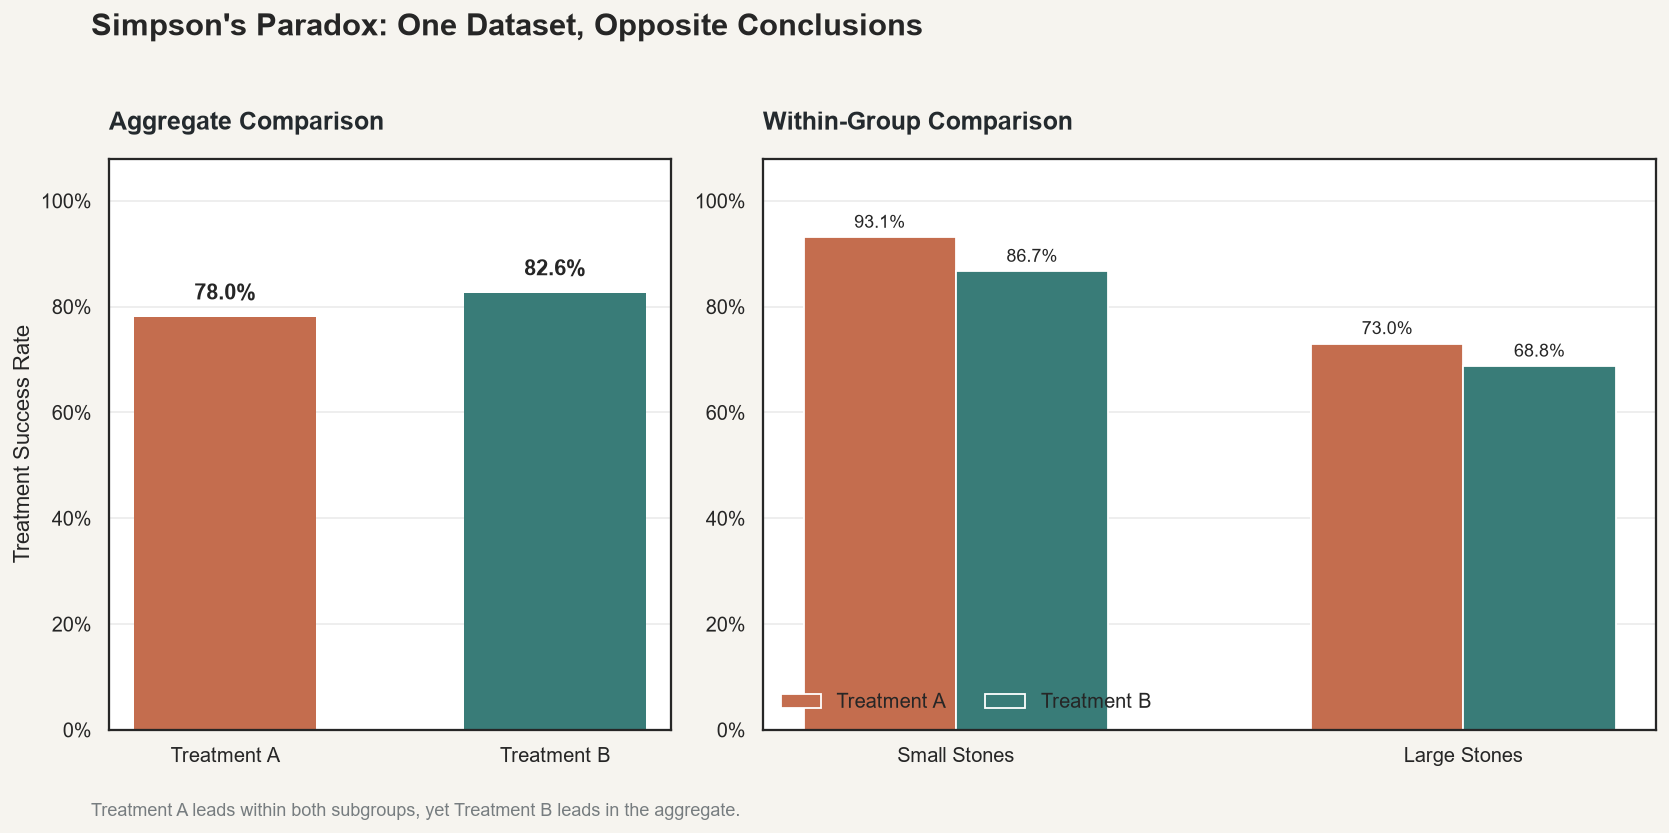

In [12]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5.8),
    gridspec_kw={"width_ratios": [0.85, 1.35]}
)

fig.patch.set_facecolor(PALETTE["paper"])

# --------------------------------------------------
# Panel 1: Aggregate comparison
# --------------------------------------------------

ax = axes[0]

aggregate_values = [
    overall_results.loc["A", "Success Rate"],
    overall_results.loc["B", "Success Rate"]
]

bars = ax.bar(
    ["Treatment A", "Treatment B"],
    aggregate_values,
    width=0.55,
    color=[
        PALETTE["terracotta"],
        PALETTE["teal"]
    ],
    edgecolor="none"
)

for bar, value in zip(bars, aggregate_values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.025,
        f"{value:.1%}",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold"
    )

ax.set_ylim(0, 1.08)
ax.yaxis.set_major_formatter(PercentFormatter(1))

ax.set_title(
    "Aggregate Comparison",
    loc="left",
    pad=16,
    fontsize=14
)

ax.set_ylabel("Treatment Success Rate")
ax.grid(axis="y", alpha=0.35)
ax.set_axisbelow(True)

# --------------------------------------------------
# Panel 2: Subgroup comparison
# --------------------------------------------------

ax = axes[1]

x = np.arange(2)
width = 0.30

small_rates = [
    subgroup_comparison.loc["Small", "A"],
    subgroup_comparison.loc["Large", "A"]
]

large_rates = [
    subgroup_comparison.loc["Small", "B"],
    subgroup_comparison.loc["Large", "B"]
]

bars_a = ax.bar(
    x - width / 2,
    small_rates,
    width,
    color=PALETTE["terracotta"],
    label="Treatment A"
)

bars_b = ax.bar(
    x + width / 2,
    large_rates,
    width,
    color=PALETTE["teal"],
    label="Treatment B"
)

for bars in [bars_a, bars_b]:
    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.018,
            f"{bar.get_height():.1%}",
            ha="center",
            fontsize=10,
            fontweight="medium"
        )

ax.set_xticks(x)
ax.set_xticklabels(["Small Stones", "Large Stones"])

ax.set_ylim(0, 1.08)
ax.yaxis.set_major_formatter(PercentFormatter(1))

ax.set_title(
    "Within-Group Comparison",
    loc="left",
    pad=16,
    fontsize=14
)

ax.grid(axis="y", alpha=0.35)
ax.set_axisbelow(True)

ax.legend(
    frameon=False,
    loc="lower left",
    ncol=2
)

# --------------------------------------------------
# Overall layout
# --------------------------------------------------

fig.suptitle(
    "Simpson's Paradox: One Dataset, Opposite Conclusions",
    fontsize=17,
    fontweight="bold",
    x=0.06,
    ha="left",
    y=1.03
)

fig.text(
    0.06,
    -0.035,
    "Treatment A leads within both subgroups, yet Treatment B leads in the aggregate.",
    fontsize=10,
    color=PALETTE["muted"]
)

plt.tight_layout()
plt.show()

**Reading the Reversal**

_The visualization places the two conclusions side by side. On the left, the aggregate comparison favours Treatment B. On the right, the subgroup comparisons consistently favour Treatment A. The difference is not caused by a change in the underlying treatment outcomes. The same observations are being analysed in both panels._

_What changes is the level at which the comparison is performed._

_The aggregate calculation combines patients with different levels of treatment difficulty. The subgroup calculation compares patients within the same stone-size category. This distinction illustrates why summary statistics should not be interpreted without considering the structure of the underlying population._

___
## **7. The Hidden Variable: Patient Composition**

The subgroup results establish that Treatment A has a higher observed success rate for both stone-size categories. However, the aggregate comparison favours Treatment B.
To understand this reversal, we need to examine how the patients were distributed between the treatments.

For Treatment A, approximately 75.14% of patients had large stones. For Treatment B, only 22.86% belonged to that category.
This difference matters because stone size is associated with treatment difficulty. Patients with large stones have lower observed success rates under both treatments.

Consequently, the overall success rate of each treatment is influenced by two factors: its success rate within each patient category and the proportion of patients belonging to each category.
The aggregate comparison combines these two effects. It does not simply measure treatment performance independently of patient composition.

**Calculate patient composition first**

In [13]:
composition = (
    grouped_data
    .pivot(
        index="Treatment",
        columns="Stone Size",
        values="Total Patients"
    )
)

composition["Total"] = composition.sum(axis=1)

composition_proportions = composition.div(
    composition["Total"],
    axis=0
)

composition_proportions

Stone Size,Large,Small,Total
Treatment,,,
A,0.751429,0.248571,1.0
B,0.228571,0.771429,1.0


**Visualise patient composition**

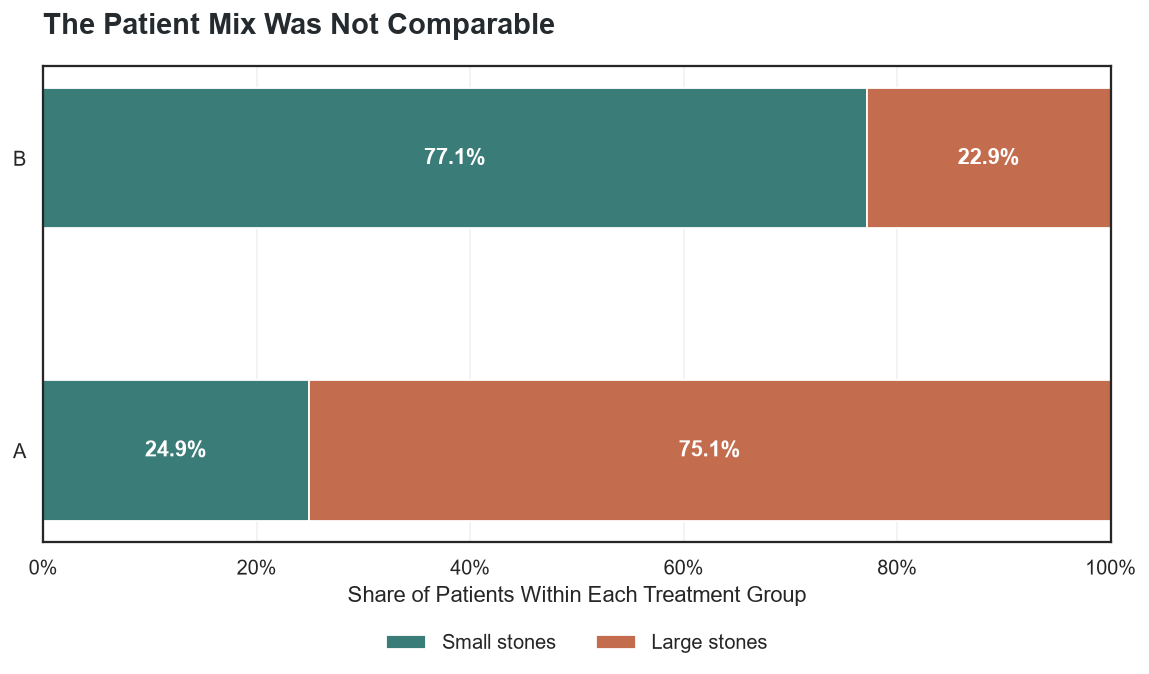

In [14]:
fig, ax = plt.subplots(figsize=(9, 5.5))

treatments = ["A", "B"]
small_share = composition_proportions.loc[treatments, "Small"].values
large_share = composition_proportions.loc[treatments, "Large"].values

ax.barh(
    treatments,
    small_share,
    color=PALETTE["teal"],
    label="Small stones",
    height=0.48
)

ax.barh(
    treatments,
    large_share,
    left=small_share,
    color=PALETTE["terracotta"],
    label="Large stones",
    height=0.48
)

for i, (small, large) in enumerate(zip(small_share, large_share)):
    ax.text(
        small / 2,
        i,
        f"{small:.1%}",
        ha="center",
        va="center",
        color="white",
        fontweight="bold",
        fontsize=12
    )

    ax.text(
        small + large / 2,
        i,
        f"{large:.1%}",
        ha="center",
        va="center",
        color="white",
        fontweight="bold",
        fontsize=12
    )

ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1))

ax.set_title(
    "The Patient Mix Was Not Comparable",
    loc="left",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Share of Patients Within Each Treatment Group")
ax.set_ylabel("")

ax.legend(
    frameon=False,
    ncol=2,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.27)
)

ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

**What the Patient Distribution Reveals**

_The two treatment groups have substantially different compositions. Almost three-quarters of Treatment A's patients had large stones, whereas more than three-quarters of Treatment B's patients had small stones._

_This creates an unequal comparison. Treatment B receives a much larger contribution from the patient category associated with higher treatment success, while Treatment A receives a much larger contribution from the category associated with lower treatment success._

_The overall success rates therefore reflect both treatment outcomes and the difficulty of the patients being treated. This is the mechanism behind the observed reversal._

___
## **8. From Aggregated Counts to Patient-Level Data**

The original dataset contains only four aggregated observations. Each observation describes the number of successful treatments and the total number of patients within a particular treatment and stone-size category.

For simulation and further analysis, we can expand these counts into individual synthetic records.

Each reconstructed record contains three variables:

- `Stone Size`: Small or Large.
- `Treatment`: A or B.
- `Outcome`: 1 for successful treatment and 0 for unsuccessful treatment.

The reconstruction preserves the original success and failure counts exactly.

Although this representation allows us to work with individual observations, it does not recover the original clinical records or any unreported patient characteristics. It is simply a patient-level representation of the information already available.

**Resconstruct individual result**

In [15]:
patient_records = []

for row in grouped_data.itertuples(index=False):

    outcomes = np.concatenate([
        np.ones(row.Successes, dtype=int),
        np.zeros(row.Failures, dtype=int)
    ])

    group_records = pd.DataFrame({
        "Stone Size": row[0],
        "Treatment": row.Treatment,
        "Outcome": outcomes
    })

    patient_records.append(group_records)

patient_df = pd.concat(
    patient_records,
    ignore_index=True
)

# Shuffle records to remove the artificial ordering
rng = np.random.default_rng(42)

patient_df = patient_df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

patient_df.head(10)

,Stone Size,Treatment,Outcome
0,Small,B,1
1,Large,A,1
2,Large,A,1
3,Small,B,1
4,Small,B,0
5,Small,B,1
6,Small,B,1
7,Small,B,1
8,Small,B,1
9,Small,B,0


**Validate reconstructed data**


In [16]:
reconstructed_summary = (
    patient_df
    .groupby(["Stone Size", "Treatment"])
    .agg(
        Successes=("Outcome", "sum"),
        Total_Patients=("Outcome", "count"),
        Success_Rate=("Outcome", "mean")
    )
    .reset_index()
)

reconstructed_summary

,Stone Size,Treatment,Successes,Total_Patients,Success_Rate
0,Large,A,192,263,0.730038
1,Large,B,55,80,0.687500
2,Small,A,81,87,0.931034
3,Small,B,234,270,0.866667


**Validation of the Reconstructed Dataset**

_The reconstructed dataset contains 700 synthetic patient records. Each record has a binary outcome, and the grouped results reproduce the original four observations exactly. This validation is important because the subsequent experiments must preserve the original subgroup outcomes before we begin changing the population composition._

_We now have a dataset that supports patient-level aggregation, repeated sampling and controlled simulation without changing the original information._

___

## **9. Direct Standardization: Making the Populations Comparable**

The aggregate success rate of a treatment is a weighted average of its subgroup success rates. The weights are determined by the proportion of patients belonging to each subgroup.

For example:
Treatment A's overall success rate is calculated using its own patient distribution:

`Overall A = (Small-stone share × A's small-stone success rate) + (Large-stone share × A's large-stone success rate)`

Treatment B is calculated using a different set of weights.
This means the two aggregate rates are not based on the same patient composition.
To investigate the effect of this difference, we can calculate standardized success rates using a common reference population.
The combined population contains 357 patients with small stones and 343 patients with large stones. These proportions will be applied to both treatments.
This produces a more directly comparable weighted average, because both treatments are evaluated against the same distribution of patient categories.

Standardization does not automatically establish a causal treatment effect. Its interpretation still depends on whether the relevant differences between patients have been adequately accounted for.

**Calculate common population weights**

In [17]:
reference_weights = (
    grouped_data
    .groupby("Stone Size")["Total Patients"]
    .sum()
)

reference_weights = (
    reference_weights / reference_weights.sum()
)

reference_weights

Stone Size
Large    0.49
Small    0.51
Name: Total Patients, dtype: float64

**Calculate standardised success rate**

In [18]:
standardized_results = (
    subgroup_results
    .assign(
        Weight=lambda df: df["Stone Size"].map(reference_weights)
    )
    .assign(
        Weighted_Success=lambda df:
            df["Success Rate"] * df["Weight"]
    )
    .groupby("Treatment")["Weighted_Success"]
    .sum()
)

standardized_comparison = pd.DataFrame({
    "Aggregate Success Rate": overall_results["Success Rate"],
    "Standardized Success Rate": standardized_results
})

standardized_comparison

,Aggregate Success Rate,Standardized Success Rate
Treatment,,
A,0.780000,0.832546
B,0.825714,0.778875


**The Result After Standardization**

_The original aggregate comparison favours Treatment B:_

- _Treatment A: 78.00%._
- _Treatment B: 82.57%._

_However, when both treatments are evaluated using the same patient distribution, the comparison reverses._

_The standardized success rates are approximately:_

- _Treatment A: 83.25%._
- _Treatment B: 77.89%._

_Treatment A now has the higher weighted success rate._

_Notice what changed: we did not modify any of the four subgroup success rates. We only changed the weights used to combine them.This demonstrates how strongly the aggregate comparison depends on population composition._

_Direct standardization is useful because it allows us to compare groups under a common reference distribution. However, it should not be mistaken for proof that the standardized difference represents a causal treatment effect. That requires additional assumptions about how treatments were assigned and whether relevant confounders have been controlled._

___
## **10. Controlled Experiment: Changing the Patient Distribution**

We now construct a controlled experiment to isolate the role of population composition.
The observed success rates within each stone-size category will remain fixed. We will vary only the proportion of small-stone patients assigned to each treatment.

For Treatment A, the expected aggregate success rate is calculated as a weighted average of its small-stone and large-stone success rates. Treatment B follows the same calculation, but its weights can differ.
This gives us two independent population-composition parameters.

If both treatments receive the same proportion of small-stone patients, their aggregate comparison should preserve the subgroup ordering because Treatment A has a higher success rate in both categories.
However, when the treatments receive substantially different patient distributions, their aggregate rates may reverse.

The purpose of this experiment is to identify the combinations of patient distributions under which Treatment A or Treatment B appears superior.

This is a controlled mathematical experiment. It does not claim that changing patient composition alone would reproduce every feature of a real clinical study.

**Define the fixed subgroup fixed rates**

In [19]:
# Observed subgroup success probabilities
A_small = 81 / 87
A_large = 192 / 263

B_small = 234 / 270
B_large = 55 / 80

# Observed proportion of small-stone patients
observed_wA = 87 / 350
observed_wB = 270 / 350

print(f"Treatment A, small-stone share: {observed_wA:.2%}")
print(f"Treatment B, small-stone share: {observed_wB:.2%}")

Treatment A, small-stone share: 24.86%
Treatment B, small-stone share: 77.14%


**Generate the composition sensitivity map**

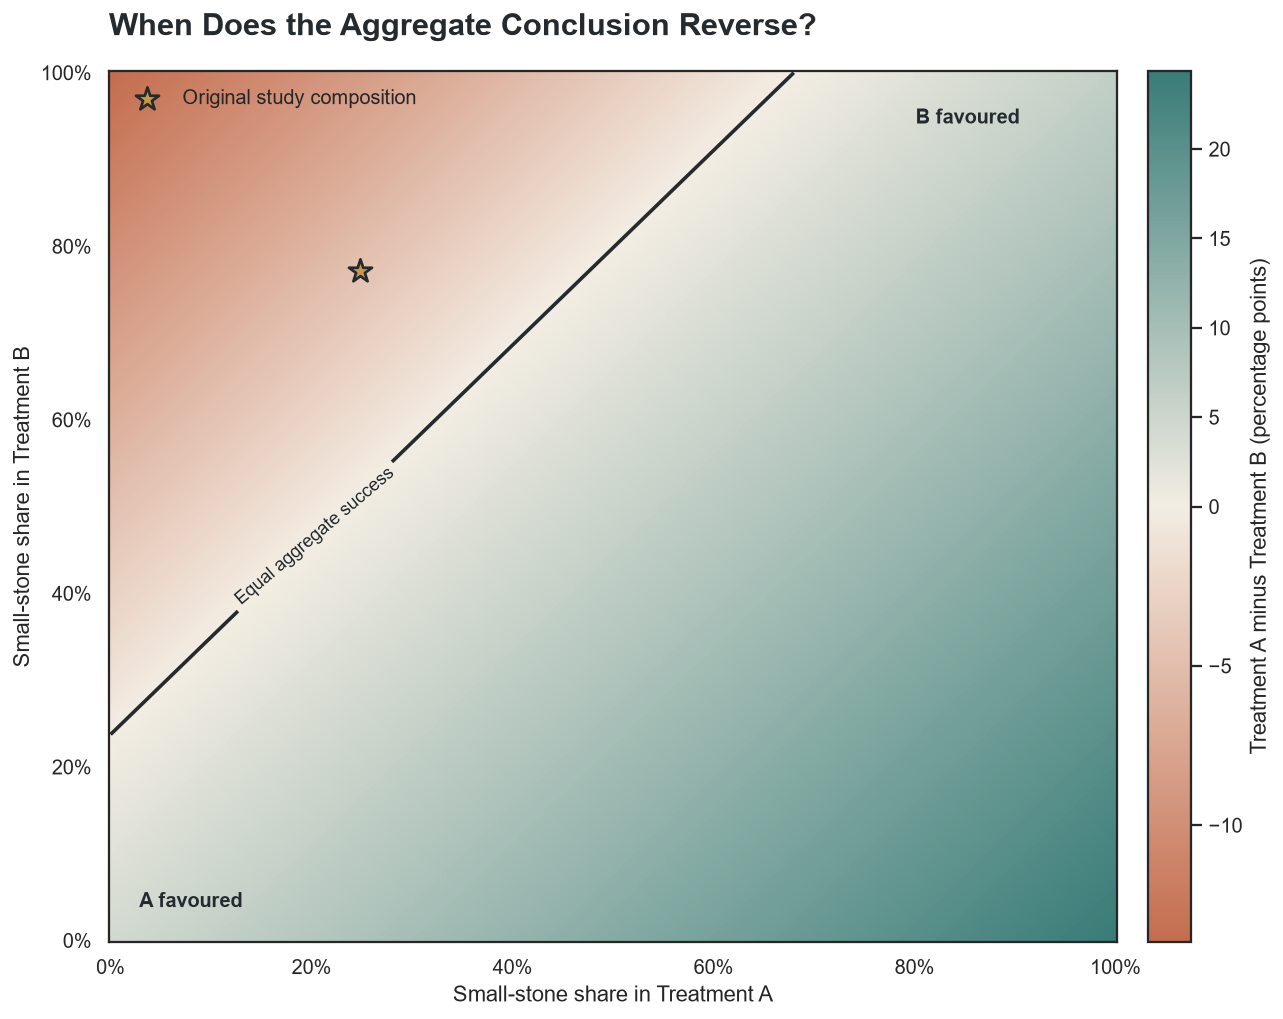

In [20]:
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

# Grid of possible small-stone proportions
wA_values = np.linspace(0, 1, 301)
wB_values = np.linspace(0, 1, 301)

WA, WB = np.meshgrid(wA_values, wB_values)

# Expected aggregate success rates
aggregate_A = (
    WA * A_small
    + (1 - WA) * A_large
)

aggregate_B = (
    WB * B_small
    + (1 - WB) * B_large
)

# Positive values favour A, negative values favour B
difference = (aggregate_A - aggregate_B) * 100

custom_cmap = LinearSegmentedColormap.from_list(
    "simpson_balance",
    [
        PALETTE["terracotta"],
        "#F3EDE3",
        PALETTE["teal"]
    ]
)

fig, ax = plt.subplots(figsize=(10.5, 8))

norm = TwoSlopeNorm(
    vmin=difference.min(),
    vcenter=0,
    vmax=difference.max()
)

image = ax.pcolormesh(
    WA,
    WB,
    difference,
    shading="auto",
    cmap=custom_cmap,
    norm=norm
)

# Boundary where both aggregate rates are equal
contour = ax.contour(
    WA,
    WB,
    difference,
    levels=[0],
    colors=[PALETTE["ink"]],
    linewidths=2
)

ax.clabel(
    contour,
    fmt={0: "Equal aggregate success"},
    inline=True,
    fontsize=10
)

# Original population composition
ax.scatter(
    observed_wA,
    observed_wB,
    color=PALETTE["gold"],
    edgecolor=PALETTE["ink"],
    linewidth=1.5,
    s=180,
    marker="*",
    zorder=5,
    label="Original study composition"
)

ax.set_title(
    "When Does the Aggregate Conclusion Reverse?",
    loc="left",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Small-stone share in Treatment A")
ax.set_ylabel("Small-stone share in Treatment B")

ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))

cbar = fig.colorbar(image, ax=ax, pad=0.025)
cbar.set_label("Treatment A minus Treatment B (percentage points)")

ax.legend(
    frameon=False,
    loc="upper left"
)

ax.text(
    0.03,
    0.04,
    "A favoured",
    transform=ax.transAxes,
    color=PALETTE["ink"],
    fontsize=11,
    fontweight="bold"
)

ax.text(
    0.80,
    0.94,
    "B favoured",
    transform=ax.transAxes,
    color=PALETTE["ink"],
    fontsize=11,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

**Interpreting the Composition Sensitivity Map**

_The visualization examines every possible combination of small-stone patient proportions for the two treatments. The horizontal axis represents the proportion of small-stone patients receiving Treatment A. The vertical axis represents the corresponding proportion for Treatment B._

_The colour indicates the difference between their expected aggregate success rates._

- _Positive values indicate that Treatment A has the higher aggregate success rate._
- _Negative values indicate that Treatment B has the higher aggregate success rate._
- _The boundary represents combinations where both treatments have equal aggregate success rates._

_The highlighted point represents the actual composition of the original study._

_It falls in the region where Treatment B appears superior, even though Treatment A has a higher success rate in both subgroups.The map demonstrates that the reversal is not an unavoidable property of the four treatment success rates. It depends on how patients are distributed between the treatment groups.When both treatments have the same patient composition, Treatment A retains its advantage because its subgroup success rates are higher in both categories._

## **11. Repeated Sampling: Introducing Random Variation**

The previous experiment demonstrated the effect of changing population composition using expected success rates.

Real clinical observations, however, are subject to sampling variation. Even when the underlying success probabilities remain unchanged, the number of successful treatments can vary from one study to another.
To investigate this, we will generate 50,000 hypothetical repetitions of the original study.

For every repetition, the subgroup sample sizes remain fixed:

- Treatment A, small stones: 87 patients.
- Treatment A, large stones: 263 patients.
- Treatment B, small stones: 270 patients.
- Treatment B, large stones: 80 patients.

The success outcomes are sampled independently within each subgroup using the corresponding observed success rate as the assumed probability.
The resulting aggregate success-rate difference will be recorded for every simulated study.

This experiment distinguishes two sources of variation:

1. The systematic difference in patient composition between the treatments.
2. Random variation in treatment outcomes across repeated samples.

The objective is to determine how frequently the aggregate comparison favours Treatment B under this particular simulation model.

**Run repeated cohort simulation**

In [21]:
rng = np.random.default_rng(2026)

N_REPETITIONS = 50_000

# Fixed subgroup sample sizes
n_A_small = 87
n_A_large = 263
n_B_small = 270
n_B_large = 80

# Simulate successes in each subgroup
sim_A_small = rng.binomial(
    n_A_small,
    A_small,
    size=N_REPETITIONS
)

sim_A_large = rng.binomial(
    n_A_large,
    A_large,
    size=N_REPETITIONS
)

sim_B_small = rng.binomial(
    n_B_small,
    B_small,
    size=N_REPETITIONS
)

sim_B_large = rng.binomial(
    n_B_large,
    B_large,
    size=N_REPETITIONS
)

# Aggregate success rates for each simulated cohort
sim_aggregate_A = (
    sim_A_small + sim_A_large
) / 350

sim_aggregate_B = (
    sim_B_small + sim_B_large
) / 350

# Difference: positive means A performs better
simulated_difference = (
    sim_aggregate_A - sim_aggregate_B
)

# How frequently does B appear better?
B_appears_better = np.mean(
    simulated_difference < 0
)

simulation_summary = pd.DataFrame({
    "Metric": [
        "Number of simulated studies",
        "Mean aggregate success rate, A",
        "Mean aggregate success rate, B",
        "Mean difference (A - B)",
        "Probability B appears better"
    ],
    "Value": [
        N_REPETITIONS,
        sim_aggregate_A.mean(),
        sim_aggregate_B.mean(),
        simulated_difference.mean(),
        B_appears_better
    ]
})

simulation_summary

,Metric,Value
0,Number of simulated studies,50000.000000
1,"Mean aggregate success rate, A",0.779946
2,"Mean aggregate success rate, B",0.825957
3,Mean difference (A - B),-0.046011
4,Probability B appears better,0.937860


**Visualise the stimulated distribution**

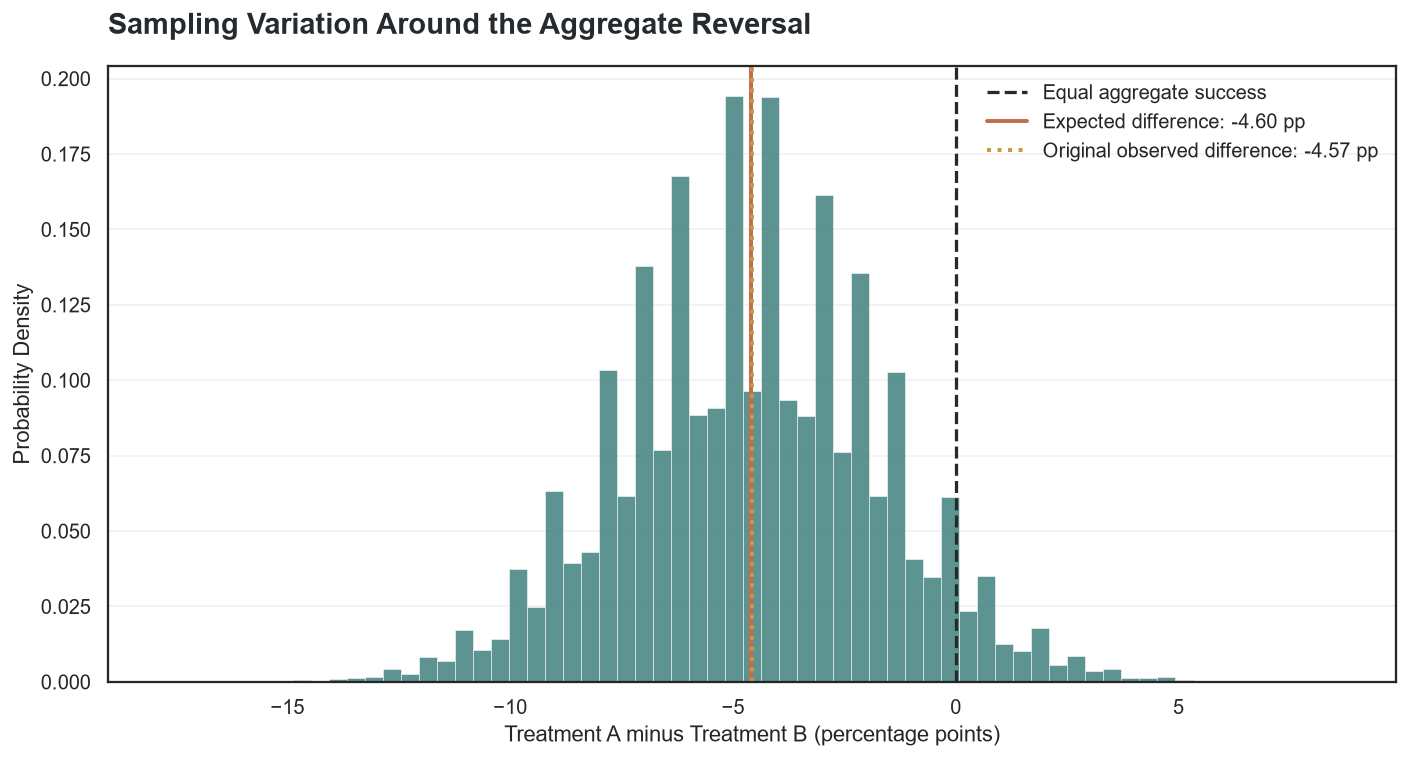

In [22]:
fig, ax = plt.subplots(figsize=(11, 6))

ax.hist(
    simulated_difference * 100,
    bins=65,
    density=True,
    color=PALETTE["teal"],
    alpha=0.82,
    edgecolor=PALETTE["surface"],
    linewidth=0.35
)

observed_difference = (
    overall_results.loc["A", "Success Rate"]
    - overall_results.loc["B", "Success Rate"]
) * 100

expected_difference = (
    sim_aggregate_A.mean()
    - sim_aggregate_B.mean()
) * 100

ax.axvline(
    0,
    color=PALETTE["ink"],
    linestyle="--",
    linewidth=1.8,
    label="Equal aggregate success"
)

ax.axvline(
    expected_difference,
    color=PALETTE["terracotta"],
    linewidth=2.2,
    label=f"Expected difference: {expected_difference:.2f} pp"
)

ax.axvline(
    observed_difference,
    color=PALETTE["gold"],
    linestyle=":",
    linewidth=2.2,
    label=f"Original observed difference: {observed_difference:.2f} pp"
)

ax.set_title(
    "Sampling Variation Around the Aggregate Reversal",
    loc="left",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Treatment A minus Treatment B (percentage points)")
ax.set_ylabel("Probability Density")

ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

**What Does the Repeated Simulation Reveal?**

_The simulation generates 50,000 hypothetical repetitions of the study while preserving the original subgroup sample sizes and assumed success probabilities. The distribution shows how the aggregate difference varies across repeated samples.A negative value indicates that Treatment B has a higher aggregate success rate. A positive value indicates that Treatment A has a higher aggregate success rate.The mean difference should be close to the expected difference implied by the subgroup success probabilities and original patient composition. The proportion of simulated studies in which Treatment B appears superior provides an estimate of how frequently the aggregate reversal occurs under this particular sampling model._

_This is not a probability that Treatment B is truly better, nor is it evidence of a causal treatment effect. It describes the behaviour of repeated samples under the assumptions built into the simulation._

___
## **12. Beyond the Paradox: Confounding and Causal Inference**

Simpson's Paradox highlights a central challenge in observational data analysis: the variables used to divide a population can influence the relationship between the outcome and the variable being investigated.

In the kidney stone example, stone size is associated with treatment success and is distributed differently between the two treatment groups.
This makes stone size an important potential confounding variable when interpreting the aggregate comparison.
A confounder is generally a variable associated with both the treatment or exposure being studied and the outcome, creating a distorted or misleading association if it is not appropriately accounted for.

The distinction matters because the aggregate success rate combines patients with different levels of treatment difficulty.

### **Association versus causation**

The subgroup results show that Treatment A has a higher observed success rate within both stone-size categories. The standardized comparison also favours Treatment A when both treatments are evaluated using the same reference distribution.
However, these findings alone do not establish that Treatment A causes better outcomes.
Other variables may influence treatment assignment and treatment success, including patient health, age, clinical history, physician decisions and other unmeasured factors.

A stronger causal conclusion would require an appropriate study design and assumptions about confounding, treatment assignment and comparability between patients.

### **Why aggregation can be dangerous**

An overall metric compresses information about the underlying population into a single number.
That compression can hide important differences between groups, particularly when the groups have unequal distributions.
The same issue appears in hiring statistics, educational performance, marketing analytics, product conversion rates and Machine Learning evaluation.
A model or intervention may appear successful overall while performing differently across important subpopulations.

The lesson is not to reject aggregate statistics. It is to understand the population structure behind them before drawing conclusions.

___
## **13. Where Simpson's Paradox Matters**

Simpson's Paradox is relevant whenever data is aggregated across groups that differ in meaningful ways.

**Medical research:** A treatment may appear more effective overall because it was administered to patients with less severe conditions. Stratifying by disease severity can reveal a different pattern.

**University admissions:** An institution may show a lower overall admission rate for one demographic group even when individual departments exhibit a different pattern. Department-level application distributions can influence the aggregate comparison.

**Business analytics:** A marketing campaign may show a higher overall conversion rate despite performing worse in individual customer segments because the campaigns reached different proportions of high-conversion and low-conversion customers.

**Machine Learning:** A model may achieve strong aggregate accuracy while performing poorly on particular subpopulations. Group-level evaluation can expose disparities hidden by a single overall metric.

**Sports analytics:** A player may have a higher overall batting average despite performing worse in individual categories if their distribution of attempts differs across those categories.

In each case, the key question is whether the aggregated populations are sufficiently comparable for the conclusion being drawn.

___
## **14. Key Findings**

The investigation demonstrates how a statistical trend can reverse when observations are combined across groups with different compositions.

1. Treatment A had a higher observed success rate than Treatment B for both small and large kidney stones.
2. The aggregate comparison favoured Treatment B, with an overall success rate of 82.57% compared with 78.00% for Treatment A.
3. Treatment A was administered predominantly to patients with large stones, while Treatment B was administered predominantly to patients with small stones.
4. The difference in patient composition influenced the overall weighted success rates.
5. Direct standardization using a common patient distribution reversed the aggregate comparison and favoured Treatment A.
6. A controlled composition experiment demonstrated that the aggregate conclusion depends on the relative distribution of patient categories.
7. Repeated sampling showed how random variation interacts with the systematic differences in population composition.
8. The example illustrates why aggregate associations should not automatically be interpreted as causal effects.

___
## **15. Limitations**

This notebook uses a simplified observational dataset to investigate Simpson's Paradox.
The patient-level records are reconstructed from aggregate counts and should not be interpreted as original clinical observations.

The controlled simulation assumes that the observed subgroup success rates represent fixed underlying probabilities. In reality, those probabilities may be uncertain and may vary with additional patient characteristics.
The standardization experiment accounts for stone-size composition but does not control for other possible confounding variables.

Finally, the repeated sampling experiment is conditional on the chosen sample sizes and assumed success probabilities. Its results should not be generalized beyond that simulation model.

These limitations reinforce an important principle: statistical adjustments can improve comparability, but they cannot compensate automatically for missing information or an unsuitable research design.

___
## **16. Conclusion**

Simpson's Paradox demonstrates that the relationship observed within individual groups can differ substantially from the relationship observed after those groups are combined.

In the kidney stone example, Treatment A has a higher success rate in both patient categories, yet Treatment B appears superior when all patients are considered together.

The reversal emerges because the treatments were administered to populations with very different distributions of stone sizes. The aggregate comparison therefore reflects both treatment outcomes and differences in patient composition.

Through subgroup analysis, direct standardization and controlled simulation, this notebook demonstrates how population structure influences statistical conclusions.

The broader lesson extends beyond this particular medical example: an aggregate statistic is only as informative as the structure it represents.

**Before asking what the data says, it is worth asking which groups were combined, how they were distributed, and what information disappeared during aggregation.**

___

_Thanks for reading._

_by_

**Abdur Rahman (Rahven)**